# Classificador de projetos de lei por tema

**Pergunta:** um modelo de linguagem natural consegue indicar o tema de um projeto de lei só pela ementa, inclusive em um ano que nunca viu?

**Fonte:** API de dados abertos da Câmara dos Deputados. Projetos de lei (PL) de 2023 e 2024, em 8 temas, mantendo apenas os que têm um único tema entre os escolhidos.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

from modelo import criar_vetorizador, limpar

SEMENTE = 42
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

## 1. Carga e qualidade dos dados

In [2]:
projetos = pd.read_csv('dados/projetos_de_lei.csv')
duplicadas = projetos['ementa'].duplicated().sum()
projetos = projetos.drop_duplicates('ementa').copy()
projetos['texto'] = projetos['ementa'].map(limpar)

print(f'{len(projetos)} projetos depois de remover {duplicadas} ementas repetidas')
print(f"Ementa mediana: {projetos['ementa'].str.len().median():.0f} caracteres")
projetos.groupby(['tema', 'ano']).size().unstack()

5152 projetos depois de remover 45 ementas repetidas
Ementa mediana: 179 caracteres


ano,2023,2024
tema,,
Defesa do Consumidor,134,110
Direito Penal,612,443
Economia,177,166
Educação,442,262
Meio Ambiente,257,247
Saúde,570,520
Trabalho e Emprego,393,311
Transporte,303,205


Ementas repetidas foram removidas para que o mesmo texto não apareça no treino e no teste.

## 2. Separação no tempo

O modelo treina com 2023 e é testado com 2024. Isso simula o uso real: classificar projetos novos, sobre assuntos que podem ainda não ter aparecido. A escolha do modelo usa só validação cruzada em 2023, e 2024 fica reservado para o teste final.

In [3]:
treino = projetos[projetos['ano'] == 2023]
teste = projetos[projetos['ano'] == 2024]
print(f'Treino: {len(treino)} | Teste: {len(teste)}')

candidatos = {
    'Maior classe (referência)': DummyClassifier(strategy='most_frequent'),
    'Naive Bayes': ComplementNB(),
    'Regressão logística': LogisticRegression(C=10, max_iter=2000, class_weight='balanced'),
    'SVM linear': LinearSVC(C=1, class_weight='balanced'),
}

dobras = StratifiedKFold(5, shuffle=True, random_state=SEMENTE)
selecao = pd.Series({
    nome: cross_val_score(make_pipeline(criar_vetorizador(), modelo), treino['texto'], treino['tema'], cv=dobras, scoring='f1_macro').mean()
    for nome, modelo in candidatos.items()
}, name='F1 macro em 2023').round(3).sort_values(ascending=False)
selecao

Treino: 2888 | Teste: 2264


Naive Bayes                  0.801
SVM linear                   0.796
Regressão logística          0.792
Maior classe (referência)    0.044
Name: F1 macro em 2023, dtype: float64

## 3. Teste final em 2024

In [4]:
nome_escolhido = selecao.index[0]
modelo_final = make_pipeline(criar_vetorizador(), candidatos[nome_escolhido]).fit(treino['texto'], treino['tema'])
previsto = modelo_final.predict(teste['texto'])

referencia = make_pipeline(criar_vetorizador(), candidatos['Maior classe (referência)']).fit(treino['texto'], treino['tema']).predict(teste['texto'])

print(f'Modelo escolhido: {nome_escolhido}')
print(f"Acurácia: {accuracy_score(teste['tema'], previsto):.3f} (referência: {accuracy_score(teste['tema'], referencia):.3f})")
print(f"F1 macro: {f1_score(teste['tema'], previsto, average='macro'):.3f} (referência: {f1_score(teste['tema'], referencia, average='macro'):.3f})")
print(classification_report(teste['tema'], previsto, digits=3))

Modelo escolhido: Naive Bayes
Acurácia: 0.765 (referência: 0.196)
F1 macro: 0.730 (referência: 0.041)
                      precision    recall  f1-score   support

Defesa do Consumidor      0.764     0.736     0.750       110
       Direito Penal      0.836     0.921     0.876       443
            Economia      0.596     0.410     0.486       166
            Educação      0.759     0.851     0.802       262
       Meio Ambiente      0.706     0.632     0.667       247
               Saúde      0.798     0.819     0.808       520
  Trabalho e Emprego      0.777     0.650     0.708       311
          Transporte      0.680     0.820     0.743       205

            accuracy                          0.765      2264
           macro avg      0.739     0.730     0.730      2264
        weighted avg      0.761     0.765     0.759      2264



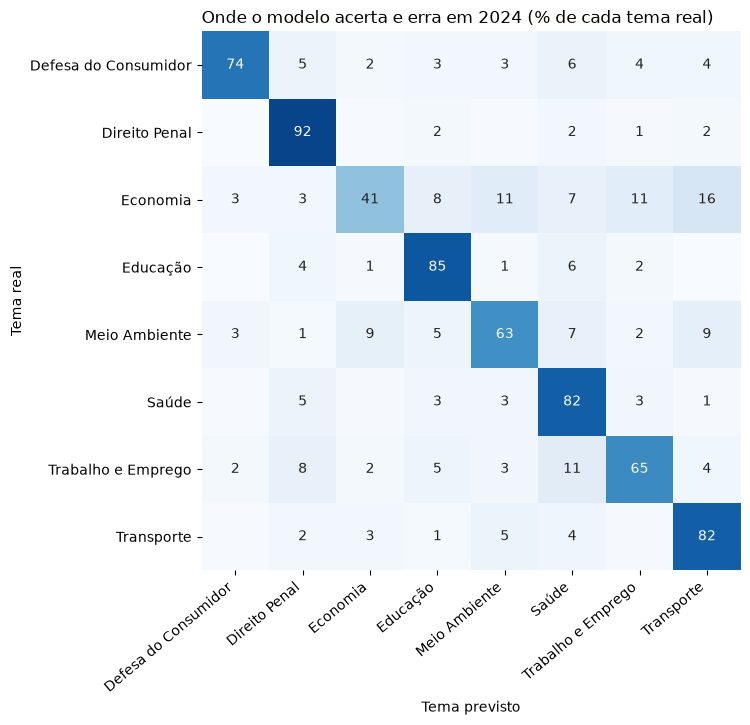

In [5]:
temas = sorted(projetos['tema'].unique())
matriz = confusion_matrix(teste['tema'], previsto, labels=temas, normalize='true') * 100

fig, ax = plt.subplots(figsize=(9, 7))
imagem = ax.imshow(matriz, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(len(temas)), temas, rotation=40, ha='right')
ax.set_yticks(range(len(temas)), temas)
for linha in range(len(temas)):
    for coluna in range(len(temas)):
        valor = matriz[linha, coluna]
        if valor >= 1:
            ax.text(coluna, linha, f'{valor:.0f}', ha='center', va='center', color='white' if valor > 55 else '#222222')
ax.set_xlabel('Tema previsto')
ax.set_ylabel('Tema real')
ax.set_title('Onde o modelo acerta e erra em 2024 (% de cada tema real)', loc='left')
ax.spines[['left', 'bottom']].set_visible(False)
fig.savefig('imagens/matriz-confusao.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. O que o modelo aprendeu

In [6]:
vetorizador = modelo_final.steps[0][1]
classificador = modelo_final.steps[1][1]
termos = vetorizador.get_feature_names_out()
coeficientes = getattr(classificador, 'coef_', None)
if coeficientes is None:
    coeficientes = classificador.feature_log_prob_
pesos = pd.DataFrame(coeficientes, index=classificador.classes_, columns=termos)
pesos = pesos - pesos.mean()  # destaca o que distingue um tema dos demais
pesos.apply(lambda linha: ', '.join(linha.nlargest(6).index), axis=1).to_frame('termos mais fortes')

,termos mais fortes
Defesa do Consumidor,"078, 11 setembro, 078 11, defesa consumidor, c..."
Direito Penal,"penal, codigo penal, 1940 codigo, decreto 848,..."
Economia,"rota turistica, turistica, cria rota, rota, cr..."
Educação,"escolas, 394 20, 20 dezembro, bases educacao, ..."
Meio Ambiente,"animais, ambiental, animais domesticos, 605 12..."
Saúde,"unico saude, sus, sistema unico, saude sus, 08..."
Trabalho e Emprego,"trabalho, consolidacao leis, leis trabalho, co..."
Transporte,"503, 1997 codigo, 503 23, codigo transito, tra..."


## 5. O risco de validar sem separar no tempo

A mesma conta com divisão aleatória mistura os dois anos, então o modelo vê no treino projetos muito parecidos com os do teste.

In [7]:
aleatoria = cross_val_score(
    make_pipeline(criar_vetorizador(), candidatos[nome_escolhido]),
    projetos['texto'], projetos['tema'], cv=dobras, scoring='f1_macro',
).mean()
print(f'F1 macro com divisão aleatória: {aleatoria:.3f}')
print(f"F1 macro treinando em 2023 e testando em 2024: {f1_score(teste['tema'], previsto, average='macro'):.3f}")

F1 macro com divisão aleatória: 0.802
F1 macro treinando em 2023 e testando em 2024: 0.730


## 6. Conclusões

- **Desempenho:** treinando só com 2023, o modelo acertou 76,5% dos projetos de 2024, contra 19,6% de escolher sempre o maior tema. O F1 macro foi de 0,730, contra 0,041.
- **Validação:** a divisão aleatória indicava F1 macro de 0,802, acima do 0,730 medido em um ano novo. Sem separar no tempo, o resultado ficaria otimista.
- **Temas:** Direito Penal (F1 de 0,876), Saúde (0,808) e Educação (0,802) têm vocabulário próprio. Economia é o pior tema (0,486), e um dos seus termos mais fortes é "rota turística", sinal de que a categoria mistura assuntos.
- **Escolha do modelo:** na validação em 2023, Naive Bayes (0,801), SVM (0,796) e regressão logística (0,792) ficaram muito próximos. A diferença é pequena demais para concluir que um é melhor em geral.

**Limites:** o modelo só conhece os 8 temas escolhidos e usa projetos com um único deles, então a base é mais fácil do que o conjunto completo, em que um projeto pode ter vários temas. Os termos mais fortes incluem números de leis, como "9.394" e "8.078", o que ajuda no acerto, mas funciona melhor com leis já citadas no treino. O modelo não deve substituir a classificação feita pela Câmara.
